# Multi-Architecture Ensemble Learning for Sideslip Angle Estimation

## Abstract

This notebook investigates multi-architecture ensemble learning for vehicle sideslip angle estimation. Unlike simple multi-seed ensembles that rely on random initialization variance, this approach leverages **architectural diversity** by combining predictions from fundamentally different neural network architectures. This creates complementary error profiles that, when aggregated, can achieve superior generalization performance.

## 1. Introduction

### 1.1 Motivation

Multi-seed ensembles (same architecture, different random seeds) often provide limited diversity because all models learn similar representations. **Multi-architecture ensembles** offer true diversity through:

1. **Different inductive biases**: RNN vs LSTM vs GRU vs BiLSTM capture different temporal patterns
2. **Complementary errors**: Each architecture excels on different data regions
3. **Robust aggregation**: Averaging diverse predictions reduces architecture-specific biases

### 1.2 Architecture Selection

We ensemble five distinct architectures:

- **VanillaRNN**: Simple RNN with ReLU activation (fast, interpretable baseline)
- **SimpleLSTM**: LSTM with gating mechanisms (handles long-term dependencies)
- **SimpleGRU**: GRU with simplified gates (efficiency vs LSTM)
- **SimpleBiLSTM**: Bidirectional LSTM (captures past and future context)
- **BiLSTMAttention**: BiLSTM + multi-head attention (sophisticated temporal modeling)

All architectures are trained with **identical hyperparameters and random seed** to isolate architectural effects.

## 2. Experimental Setup

### 2.1 Dependencies and Environment Configuration

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
import copy
from datetime import datetime
warnings.filterwarnings('ignore')

# Configure visualization
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

# Add project root to path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

# Import custom utilities
from utils.reproducibility_utils import seed_everything, seed_worker
from utils.data_loadingV2 import load_data, load_test_data
from utils.kaggle_metric import score as kaggle_score
from utils.band_mapping import load_band_mapping, calculate_band_mae

# Import model architectures
from models.vanilla_rnn import VanillaRNN
from models.simple_lstm import SimpleLSTM
from models.simple_gru import SimpleGRU
from models.simple_bilstm import SimpleBiLSTM
from models.bilstm_attention import BiLSTMAttention

# Verify computational environment
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation device: {device}")

PyTorch version: 2.9.1+cu128
CUDA available: True
Computation device: cuda


### 2.2 Hyperparameter Configuration

All architectures use identical hyperparameters (except architecture-specific parameters like attention heads) to ensure fair comparison.

In [2]:
# Path configuration
TRAIN_PATH = PROJECT_ROOT / "datasets_challenge" / "train"
TEST_PATH = PROJECT_ROOT / "datasets_challenge" / "test"
DIST_CSV = PROJECT_ROOT / "datasets_challenge" / "sideSlip_distribution.csv"
OUTPUT_DIR = PROJECT_ROOT / "Ensemble_Approach" / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Ensemble configuration
SEED = 42  # Single seed for all models (isolates architectural differences)

# Shared hyperparameters
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.0
BATCH_SIZE = 256
SEQUENCE_LENGTH = 20
VAL_RATIO = 0.2
NUM_EPOCHS = 50
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-5

# Architecture definitions
ARCHITECTURES = {
    'VanillaRNN': {
        'class': VanillaRNN,
        'params': {
            'input_size': 22,  # Will be updated from data
            'hidden_size': HIDDEN_SIZE,
            'num_layers': NUM_LAYERS,
            'dropout': DROPOUT
        },
        'color': '#e74c3c',  # Red
        'description': 'Simple RNN with ReLU activation'
    },
    'SimpleLSTM': {
        'class': SimpleLSTM,
        'params': {
            'input_size': 22,
            'hidden_size': HIDDEN_SIZE,
            'num_layers': NUM_LAYERS,
            'dropout': DROPOUT
        },
        'color': '#3498db',  # Blue
        'description': 'LSTM with gating mechanisms'
    },
    'SimpleGRU': {
        'class': SimpleGRU,
        'params': {
            'input_size': 22,
            'hidden_size': HIDDEN_SIZE,
            'num_layers': NUM_LAYERS,
            'dropout': DROPOUT
        },
        'color': '#2ecc71',  # Green
        'description': 'GRU with simplified gates'
    },
    'SimpleBiLSTM': {
        'class': SimpleBiLSTM,
        'params': {
            'input_size': 22,
            'hidden_size': HIDDEN_SIZE,
            'num_layers': NUM_LAYERS,
            'dropout': DROPOUT
        },
        'color': '#9b59b6',  # Purple
        'description': 'Bidirectional LSTM'
    },
    'BiLSTMAttention': {
        'class': BiLSTMAttention,
        'params': {
            'input_size': 22,
            'hidden_size': HIDDEN_SIZE,
            'num_layers': 2,  # Attention works better with 2 layers
            'num_heads': 4,
            'dropout': DROPOUT
        },
        'color': '#f39c12',  # Orange
        'description': 'BiLSTM with multi-head attention'
    }
}

# Display configuration
print("\n" + "="*80)
print("MULTI-ARCHITECTURE ENSEMBLE CONFIGURATION")
print("="*80)
print(f"Number of architectures: {len(ARCHITECTURES)}")
print(f"Random seed: {SEED} (shared across all models)")
print(f"\nArchitectures:")
for name, config in ARCHITECTURES.items():
    print(f"  - {name:20s}: {config['description']}")
print(f"\nTraining configuration:")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Batch size: {BATCH_SIZE}")
print("="*80 + "\n")


MULTI-ARCHITECTURE ENSEMBLE CONFIGURATION
Number of architectures: 5
Random seed: 42 (shared across all models)

Architectures:
  - VanillaRNN          : Simple RNN with ReLU activation
  - SimpleLSTM          : LSTM with gating mechanisms
  - SimpleGRU           : GRU with simplified gates
  - SimpleBiLSTM        : Bidirectional LSTM
  - BiLSTMAttention     : BiLSTM with multi-head attention

Training configuration:
  Epochs: 50
  Learning rate: 0.0003
  Batch size: 256



## 3. Data Preparation

### 3.1 Dataset Loading and Preprocessing

In [3]:
# Initialize random state for reproducibility
seed_everything(SEED)

# Load and partition data
train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path=str(TRAIN_PATH),
    val_ratio=VAL_RATIO,
    sequence_length=SEQUENCE_LENGTH,
    target='sideSlip',
    threshold=True,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=BATCH_SIZE,
    scaling=True,
    seed=SEED,
    shuffle=True
)

# Display dataset statistics
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Approximate training samples: {len(train_loader) * BATCH_SIZE:,}")
print(f"Approximate validation samples: {len(val_loader) * BATCH_SIZE:,}")

# Get actual input dimension from data
for X, y in train_loader:
    input_size = X.shape[2]
    print(f"\nInput tensor shape: {X.shape}")
    print(f"  - Batch size: {X.shape[0]}")
    print(f"  - Sequence length: {X.shape[1]}")
    print(f"  - Feature dimension: {X.shape[2]}")
    print(f"Target tensor shape: {y.shape}")
    break

# Update all architecture configurations with actual input_size
for arch_name in ARCHITECTURES:
    ARCHITECTURES[arch_name]['params']['input_size'] = input_size

print(f"\n✅ Updated all architectures with input_size={input_size}")

# Load band mapping for evaluation
band_dict = load_band_mapping(str(DIST_CSV))
print(f"✅ Loaded band mapping for stratified evaluation")

V5 Data Loader: Stratified Temporal Split

Processing 22 files...
Total groups after threshold: 42

Train: Many=90.0%, Medium=7.8%, Few=2.2%
Val:   Many=95.8%, Medium=2.8%, Few=1.3%

Train: 111,841 sequences | Val: 25,239 sequences

Training batches: 437
Validation batches: 99
Approximate training samples: 111,872
Approximate validation samples: 25,344

Input tensor shape: torch.Size([256, 20, 22])
  - Batch size: 256
  - Sequence length: 20
  - Feature dimension: 22
Target tensor shape: torch.Size([256])

✅ Updated all architectures with input_size=22
✅ Loaded band mapping for stratified evaluation


## 4. Training Framework

### 4.1 Training and Evaluation Functions

In [4]:
def train_architecture(arch_name, model_class, model_params, train_loader, val_loader, 
                       device, band_dict, seed=SEED, epochs=NUM_EPOCHS,
                       lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, verbose=True):
    """
    Train a single architecture.
    
    Args:
        arch_name (str): Architecture name for logging
        model_class: Model class to instantiate
        model_params (dict): Model hyperparameters
        train_loader (DataLoader): Training data loader
        val_loader (DataLoader): Validation data loader
        device (torch.device): Computation device
        band_dict (dict): Band mapping for evaluation
        seed (int): Random seed
        epochs (int): Training epochs
        lr (float): Learning rate
        weight_decay (float): L2 regularization
        verbose (bool): Print progress
    
    Returns:
        model, metrics, history
    """
    # Set random seed
    seed_everything(seed)
    
    # Initialize model
    model = model_class(**model_params).to(device)
    
    if verbose:
        total_params = sum(p.numel() for p in model.parameters())
        print(f"\n{'='*80}")
        print(f"Training {arch_name}")
        print(f"{'='*80}")
        print(f"Parameters: {total_params:,}")
    
    # Loss and optimizer
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=lr * 0.01
    )
    
    # Training history
    history = {'train_loss': [], 'val_loss': [], 'learning_rate': []}
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    for epoch in range(epochs):
        # Training phase
        model.train()
        train_losses = []
        
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            if y.dim() == 1:
                y = y.unsqueeze(1)
            
            optimizer.zero_grad()
            predictions = model(X)
            loss = criterion(predictions, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_losses.append(loss.item())
        
        # Validation phase
        model.eval()
        val_losses = []
        
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                if y.dim() == 1:
                    y = y.unsqueeze(1)
                
                predictions = model(X)
                loss = criterion(predictions, y)
                val_losses.append(loss.item())
        
        scheduler.step()
        
        # Record history
        epoch_train_loss = np.mean(train_losses)
        epoch_val_loss = np.mean(val_losses)
        current_lr = optimizer.param_groups[0]['lr']
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['learning_rate'].append(current_lr)
        
        # Save best model
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
        
        # Print progress
        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:03d}/{epochs}: train={epoch_train_loss:.4f}, val={epoch_val_loss:.4f}, lr={current_lr:.2e}")
    
    # Restore best model
    model.load_state_dict(best_model_state)
    
    # Evaluate
    metrics = evaluate_model(model, val_loader, device, band_dict)
    
    if verbose:
        print(f"\nFinal metrics:")
        print(f"  Overall MAE: {metrics['val_mae']:.4f}")
        print(f"  Few-shot: {metrics.get('few_mae', 'N/A'):.4f}")
        print(f"  Medium-shot: {metrics.get('medium_mae', 'N/A'):.4f}")
        print(f"  Many-shot: {metrics.get('many_mae', 'N/A'):.4f}")
    
    return model, metrics, history


def evaluate_model(model, data_loader, device, band_dict):
    """Evaluate model with band-specific metrics."""
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for X, y in data_loader:
            X = X.to(device)
            predictions = model(X).cpu().numpy().flatten()
            targets = y.numpy().flatten() if y.dim() > 1 else y.numpy()
            
            all_preds.extend(predictions)
            all_targets.extend(targets)
    
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # Overall MAE
    val_mae = np.mean(np.abs(all_preds - all_targets))
    metrics = {'val_mae': val_mae}
    
    # Band-specific MAE
    try:
        band_metrics = calculate_band_mae(all_preds, all_targets, band_dict)
        metrics.update(band_metrics)
    except Exception as e:
        print(f"Warning: Could not calculate band metrics: {e}")
    
    return metrics


def get_model_predictions(model, data_loader, device):
    """Get predictions from a single model."""
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for X, y in data_loader:
            X = X.to(device)
            predictions = model(X).cpu().numpy().flatten()
            targets = y.numpy().flatten() if y.dim() > 1 else y.numpy()
            
            all_preds.extend(predictions)
            all_targets.extend(targets)
    
    return np.array(all_preds), np.array(all_targets)

print("✅ Training framework loaded")

✅ Training framework loaded


### 4.2 Baseline VanillaRNN Training

Before training the multi-architecture ensemble, we establish a baseline by training a standalone VanillaRNN model. This baseline represents standard single-architecture performance and serves as the primary comparison point for evaluating the benefits of architectural diversity.

In [5]:
print("\n" + "="*80)
print("BASELINE VANILLARNN TRAINING")
print("="*80)
print(f"Training standalone VanillaRNN (seed {SEED}) as baseline comparison")

# Train baseline model
baseline_model, baseline_metrics, baseline_history = train_architecture(
    arch_name="Baseline_VanillaRNN",
    model_class=VanillaRNN,
    model_params=ARCHITECTURES['VanillaRNN']['params'],
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    band_dict=band_dict,
    verbose=True
)

# Get baseline predictions
baseline_preds, baseline_targets = get_model_predictions(baseline_model, val_loader, device)
baseline_mae = baseline_metrics['val_mae']

# Display baseline results
print("\n" + "="*80)
print("BASELINE MODEL RESULTS")
print("="*80)
print(f"Validation MAE:        {baseline_mae:.4f}")
print(f"Few-shot MAE:          {baseline_metrics.get('few_mae', 'N/A'):.4f}")
print(f"Medium-shot MAE:       {baseline_metrics.get('medium_mae', 'N/A'):.4f}")
print(f"Many-shot MAE:         {baseline_metrics.get('many_mae', 'N/A'):.4f}")
print("="*80 + "\n")


BASELINE VANILLARNN TRAINING
Training standalone VanillaRNN (seed 42) as baseline comparison

Training Baseline_VanillaRNN
Parameters: 9,857
Epoch 010/50: train=0.1679, val=0.1807, lr=2.72e-04
Epoch 020/50: train=0.1533, val=0.1680, lr=1.97e-04
Epoch 030/50: train=0.1464, val=0.1630, lr=1.06e-04
Epoch 040/50: train=0.1413, val=0.1618, lr=3.14e-05
Epoch 050/50: train=0.1396, val=0.1669, lr=3.00e-06

Final metrics:
  Overall MAE: 0.1578
  Few-shot: 0.3978
  Medium-shot: 0.2502
  Many-shot: 0.1383

BASELINE MODEL RESULTS
Validation MAE:        0.1578
Few-shot MAE:          0.3978
Medium-shot MAE:       0.2502
Many-shot MAE:         0.1383



## 5. Train All Architectures

### 5.1 Sequential Training

Train each architecture independently with the same random seed and hyperparameters.

In [6]:
# Storage for results
trained_models = {}
architecture_metrics = {}
architecture_histories = {}
architecture_predictions = {}

print("\n" + "="*80)
print(f"TRAINING {len(ARCHITECTURES)} ARCHITECTURES")
print("="*80)

for i, (arch_name, config) in enumerate(ARCHITECTURES.items()):
    print(f"\n[{i+1}/{len(ARCHITECTURES)}] {arch_name}")
    print("-" * 80)
    
    # Train architecture
    model, metrics, history = train_architecture(
        arch_name=arch_name,
        model_class=config['class'],
        model_params=config['params'],
        train_loader=train_loader,
        val_loader=val_loader,
        device=device,
        band_dict=band_dict,
        verbose=True
    )
    
    # Store results
    trained_models[arch_name] = model
    architecture_metrics[arch_name] = metrics
    architecture_histories[arch_name] = history
    
    # Get predictions for ensemble
    preds, targets = get_model_predictions(model, val_loader, device)
    architecture_predictions[arch_name] = preds

# Store targets (same for all models)
val_targets = targets

print("\n" + "="*80)
print("ALL ARCHITECTURES TRAINED SUCCESSFULLY")
print("="*80)


TRAINING 5 ARCHITECTURES

[1/5] VanillaRNN
--------------------------------------------------------------------------------

Training VanillaRNN
Parameters: 9,857
Epoch 010/50: train=0.1679, val=0.1807, lr=2.72e-04
Epoch 020/50: train=0.1533, val=0.1680, lr=1.97e-04
Epoch 030/50: train=0.1464, val=0.1630, lr=1.06e-04
Epoch 040/50: train=0.1413, val=0.1618, lr=3.14e-05
Epoch 050/50: train=0.1396, val=0.1669, lr=3.00e-06

Final metrics:
  Overall MAE: 0.1578
  Few-shot: 0.3978
  Medium-shot: 0.2502
  Many-shot: 0.1383

[2/5] SimpleLSTM
--------------------------------------------------------------------------------

Training SimpleLSTM
Parameters: 26,753
Epoch 010/50: train=0.1437, val=0.1579, lr=2.72e-04
Epoch 020/50: train=0.1279, val=0.1511, lr=1.97e-04
Epoch 030/50: train=0.1182, val=0.1474, lr=1.06e-04
Epoch 040/50: train=0.1140, val=0.1537, lr=3.14e-05
Epoch 050/50: train=0.1121, val=0.1514, lr=3.00e-06

Final metrics:
  Overall MAE: 0.1464
  Few-shot: 0.3969
  Medium-shot: 0.2369

## 6. Results Analysis

### 6.1 Individual Architecture Performance

In [7]:
# Create summary table
summary_data = []
for arch_name, metrics in architecture_metrics.items():
    summary_data.append({
        'Architecture': arch_name,
        'Val_MAE': metrics['val_mae'],
        'Few_Shot_MAE': metrics.get('few_mae', np.nan),
        'Medium_Shot_MAE': metrics.get('medium_mae', np.nan),
        'Many_Shot_MAE': metrics.get('many_mae', np.nan)
    })

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Val_MAE')

print("\n" + "="*80)
print("INDIVIDUAL ARCHITECTURE PERFORMANCE")
print("="*80)
print(summary_df.to_string(index=False))
print("\n" + "-"*80)
print(f"Mean validation MAE: {summary_df['Val_MAE'].mean():.4f} ± {summary_df['Val_MAE'].std():.4f}")
print(f"Best architecture: {summary_df.iloc[0]['Architecture']} (MAE: {summary_df.iloc[0]['Val_MAE']:.4f})")
print(f"Worst architecture: {summary_df.iloc[-1]['Architecture']} (MAE: {summary_df.iloc[-1]['Val_MAE']:.4f})")
print(f"Performance range: {summary_df['Val_MAE'].max() - summary_df['Val_MAE'].min():.4f}")
print("="*80 + "\n")


INDIVIDUAL ARCHITECTURE PERFORMANCE
   Architecture  Val_MAE  Few_Shot_MAE  Medium_Shot_MAE  Many_Shot_MAE
     SimpleLSTM 0.146395      0.396864         0.236884       0.129757
   SimpleBiLSTM 0.147283      0.365656         0.229647       0.126947
      SimpleGRU 0.148494      0.359445         0.261957       0.127308
BiLSTMAttention 0.149945      0.343867         0.248423       0.132803
     VanillaRNN 0.157803      0.397814         0.250167       0.138321

--------------------------------------------------------------------------------
Mean validation MAE: 0.1500 ± 0.0046
Best architecture: SimpleLSTM (MAE: 0.1464)
Worst architecture: VanillaRNN (MAE: 0.1578)
Performance range: 0.0114



### 6.2 Ensemble Prediction

Aggregate predictions from all architectures via mean averaging.

In [9]:
# Stack all predictions
all_arch_preds = np.stack([architecture_predictions[name] for name in ARCHITECTURES.keys()], axis=0)

# Ensemble predictions (mean)
ensemble_preds = np.mean(all_arch_preds, axis=0)
ensemble_mae = np.mean(np.abs(ensemble_preds - val_targets))

# Calculate ensemble metrics with band-specific evaluation
ensemble_metrics = {'val_mae': ensemble_mae}
try:
    band_metrics = calculate_band_mae(ensemble_preds, val_targets, band_dict)
    ensemble_metrics.update(band_metrics)
except Exception as e:
    print(f"Warning: Could not calculate band metrics: {e}")

# Comparison metrics
mean_arch_mae = summary_df['Val_MAE'].mean()
best_arch_mae = summary_df['Val_MAE'].min()
best_arch_name = summary_df.iloc[0]['Architecture']

improvement_over_baseline = ((baseline_mae - ensemble_mae) / baseline_mae) * 100
improvement_over_mean = ((mean_arch_mae - ensemble_mae) / mean_arch_mae) * 100
improvement_over_best = ((best_arch_mae - ensemble_mae) / best_arch_mae) * 100

print("\n" + "="*80)
print("ENSEMBLE PERFORMANCE")
print("="*80)
print(f"Aggregation method: Mean averaging ({len(ARCHITECTURES)} architectures)")
print(f"  Baseline VanillaRNN MAE:   {baseline_mae:.4f} (standalone, seed {SEED})")
print(f"  Ensemble MAE:              {ensemble_mae:.4f}")
print(f"  Mean architecture MAE:     {mean_arch_mae:.4f}")
print(f"  Best architecture MAE:     {best_arch_mae:.4f} ({best_arch_name})")
print(f"\nRelative improvements:")
print(f"  vs. Baseline VanillaRNN:   {improvement_over_baseline:+.2f}% 🎯")
print(f"  vs. Mean architecture:     {improvement_over_mean:+.2f}%")
print(f"  vs. Best architecture:     {improvement_over_best:+.2f}%")

if improvement_over_best > 0:
    print(f"\n✅ Ensemble BEATS best individual architecture!")
else:
    print(f"\n⚠️  Ensemble does NOT beat best individual architecture")
    print(f"    This suggests insufficient architectural diversity")

print(f"\nBand-specific results:")
print(f"  Few-shot MAE:     {ensemble_metrics.get('few_mae', 'N/A'):.4f}")
print(f"  Medium-shot MAE:  {ensemble_metrics.get('medium_mae', 'N/A'):.4f}")

print(f"  Many-shot MAE:    {ensemble_metrics.get('many_mae', 'N/A'):.4f}")
print("="*80 + "\n")


ENSEMBLE PERFORMANCE
Aggregation method: Mean averaging (5 architectures)
  Baseline VanillaRNN MAE:   0.1578 (standalone, seed 42)
  Ensemble MAE:              0.1416
  Mean architecture MAE:     0.1500
  Best architecture MAE:     0.1464 (SimpleLSTM)

Relative improvements:
  vs. Baseline VanillaRNN:   +10.26% 🎯
  vs. Mean architecture:     +5.58%
  vs. Best architecture:     +3.27%

✅ Ensemble BEATS best individual architecture!

Band-specific results:
  Few-shot MAE:     0.3615
  Medium-shot MAE:  0.2311
  Many-shot MAE:    0.1232



### 6.3 Architecture Correlation Analysis

Analyze prediction correlations to understand diversity.

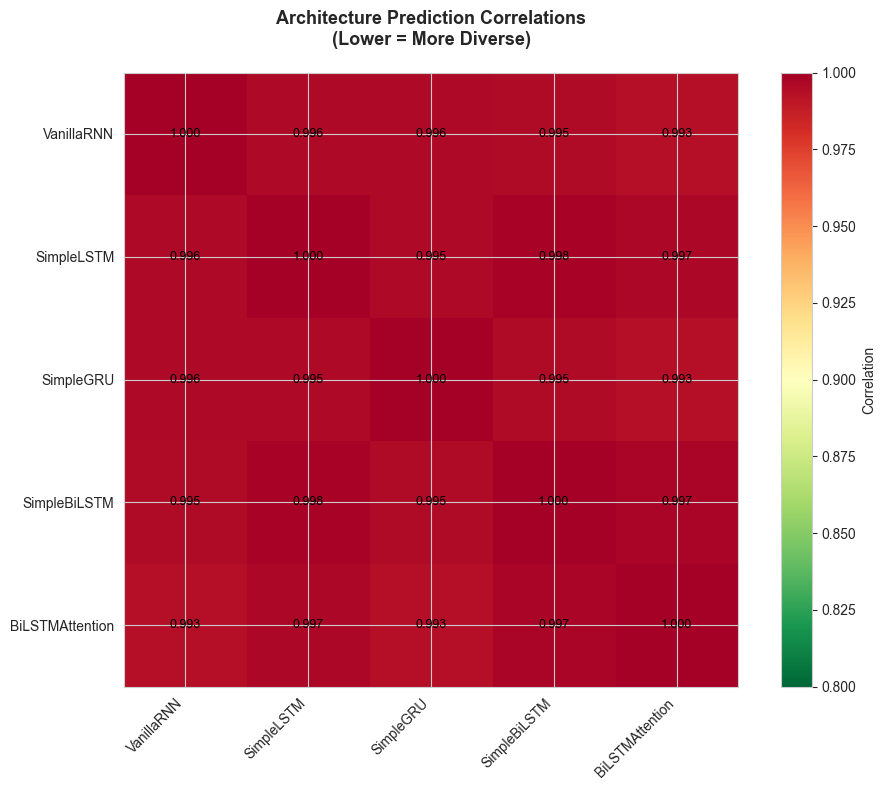


Architecture diversity analysis:
  Mean correlation: 0.9955
  Min correlation:  0.9931 (most diverse pair)
  Max correlation: 0.9980 (least diverse pair)
  ⚠️  Low diversity (mean correlation >= 0.95)


In [10]:
# Calculate prediction correlations
arch_names = list(ARCHITECTURES.keys())
n_arch = len(arch_names)
correlation_matrix = np.zeros((n_arch, n_arch))

for i, name1 in enumerate(arch_names):
    for j, name2 in enumerate(arch_names):
        corr = np.corrcoef(architecture_predictions[name1], architecture_predictions[name2])[0, 1]
        correlation_matrix[i, j] = corr

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlation_matrix, cmap='RdYlGn_r', vmin=0.8, vmax=1.0)

# Set ticks and labels
ax.set_xticks(np.arange(n_arch))
ax.set_yticks(np.arange(n_arch))
ax.set_xticklabels(arch_names, rotation=45, ha='right')
ax.set_yticklabels(arch_names)

# Add correlation values
for i in range(n_arch):
    for j in range(n_arch):
        text = ax.text(j, i, f'{correlation_matrix[i, j]:.3f}',
                      ha='center', va='center', color='black', fontsize=9)

ax.set_title('Architecture Prediction Correlations\n(Lower = More Diverse)', fontsize=13, fontweight='bold', pad=20)
plt.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'architecture_correlations.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate diversity metrics
off_diagonal = correlation_matrix[np.triu_indices(n_arch, k=1)]
mean_correlation = off_diagonal.mean()
min_correlation = off_diagonal.min()
max_correlation = off_diagonal.max()

print(f"\nArchitecture diversity analysis:")
print(f"  Mean correlation: {mean_correlation:.4f}")
print(f"  Min correlation:  {min_correlation:.4f} (most diverse pair)")
print(f"  Max correlation: {max_correlation:.4f} (least diverse pair)")

if mean_correlation < 0.95:
    print(f"  ✅ Good diversity (mean correlation < 0.95)")
else:
    print(f"  ⚠️  Low diversity (mean correlation >= 0.95)")

## 7. Visualization

### 7.1 Performance Comparison Bar Chart

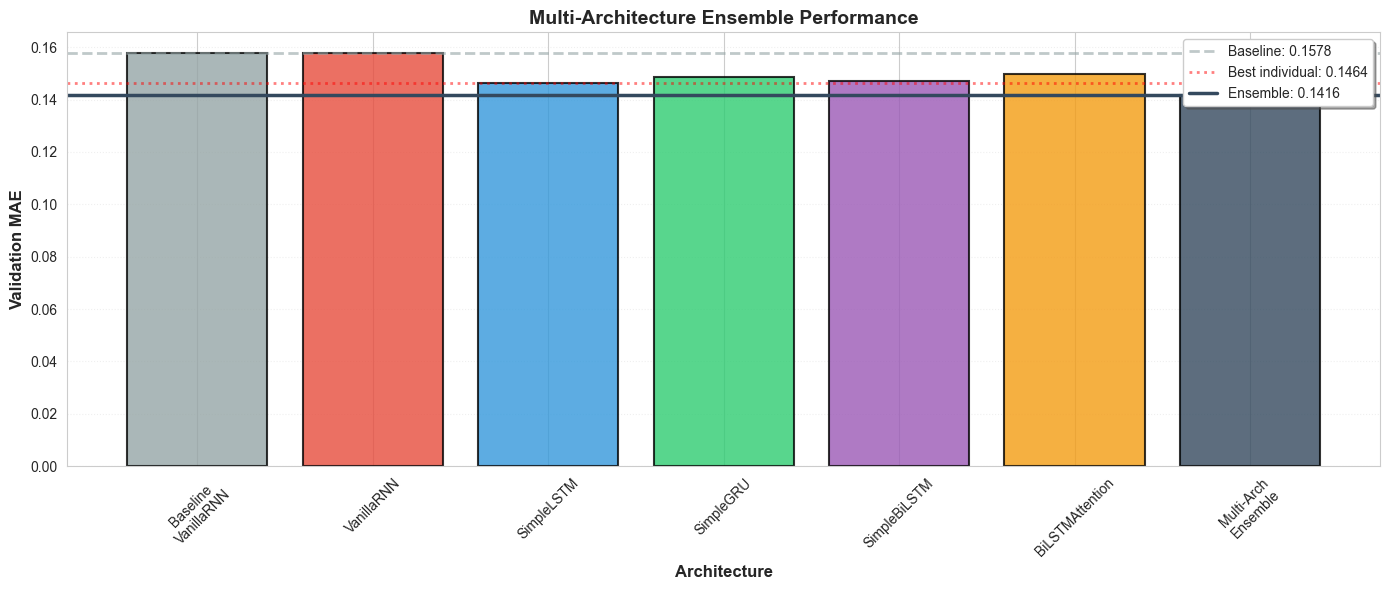

In [11]:
# Prepare data for plotting
plot_names = ['Baseline\nVanillaRNN'] + list(ARCHITECTURES.keys()) + ['Multi-Arch\nEnsemble']
plot_maes = [baseline_mae] + [architecture_metrics[name]['val_mae'] for name in ARCHITECTURES.keys()] + [ensemble_mae]
plot_colors = ['#95a5a6'] + [ARCHITECTURES[name]['color'] for name in ARCHITECTURES.keys()] + ['#34495e']

# Create bar chart
fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(plot_names, plot_maes, color=plot_colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Highlight baseline, best architecture and ensemble
ax.axhline(y=baseline_mae, color='#95a5a6', linestyle='--', linewidth=2, alpha=0.6,
           label=f'Baseline: {baseline_mae:.4f}')
ax.axhline(y=best_arch_mae, color='red', linestyle=':', linewidth=2, alpha=0.5,
           label=f'Best individual: {best_arch_mae:.4f}')
ax.axhline(y=ensemble_mae, color='#34495e', linestyle='-', linewidth=2.5,
           label=f'Ensemble: {ensemble_mae:.4f}')

ax.set_ylabel('Validation MAE', fontsize=12, fontweight='bold')
ax.set_xlabel('Architecture', fontsize=12, fontweight='bold')
ax.set_title('Multi-Architecture Ensemble Performance', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', frameon=True, shadow=True)
ax.grid(axis='y', alpha=0.3, linestyle=':')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'multi_architecture_performance.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.2 Training Dynamics

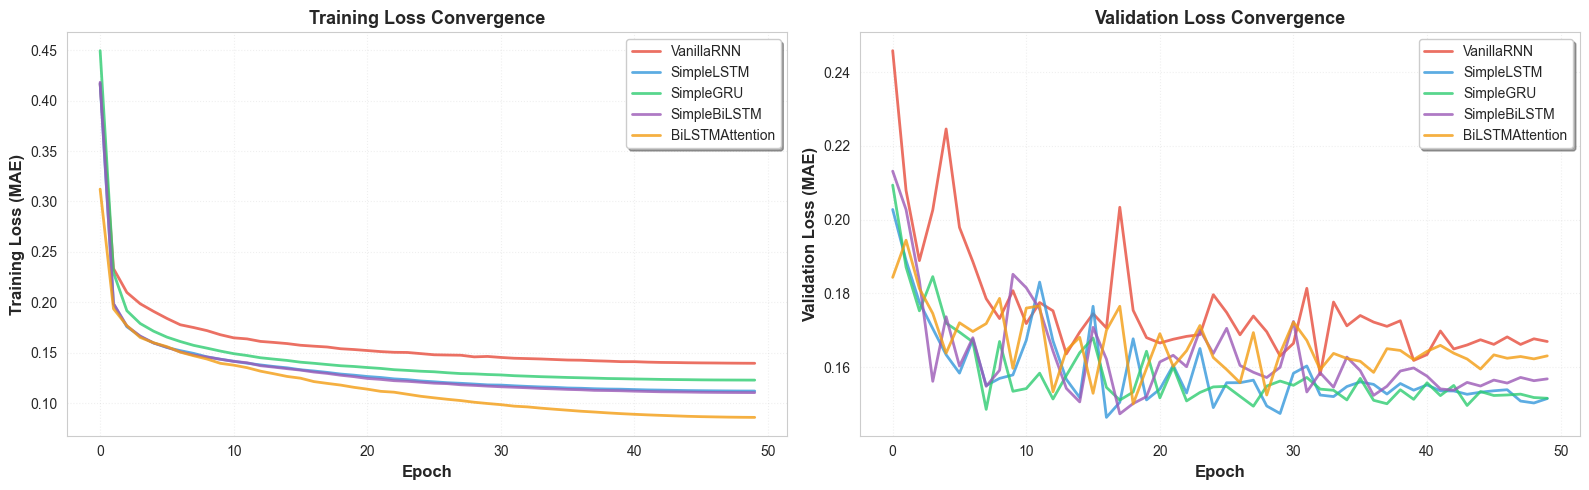

In [12]:
# Plot training histories
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Training loss
for arch_name, history in architecture_histories.items():
    color = ARCHITECTURES[arch_name]['color']
    axes[0].plot(history['train_loss'], label=arch_name, color=color, alpha=0.8, linewidth=2)

axes[0].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Training Loss (MAE)', fontsize=12, fontweight='bold')
axes[0].set_title('Training Loss Convergence', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, shadow=True)
axes[0].grid(alpha=0.3, linestyle=':')

# Validation loss
for arch_name, history in architecture_histories.items():
    color = ARCHITECTURES[arch_name]['color']
    axes[1].plot(history['val_loss'], label=arch_name, color=color, alpha=0.8, linewidth=2)

axes[1].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Validation Loss (MAE)', fontsize=12, fontweight='bold')
axes[1].set_title('Validation Loss Convergence', fontsize=13, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, shadow=True)
axes[1].grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'multi_architecture_training.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.3 Baseline vs Best Architecture vs Ensemble Comparison

Three-way comparison showing the progression from baseline single-architecture to best ensemble member to multi-architecture ensemble.

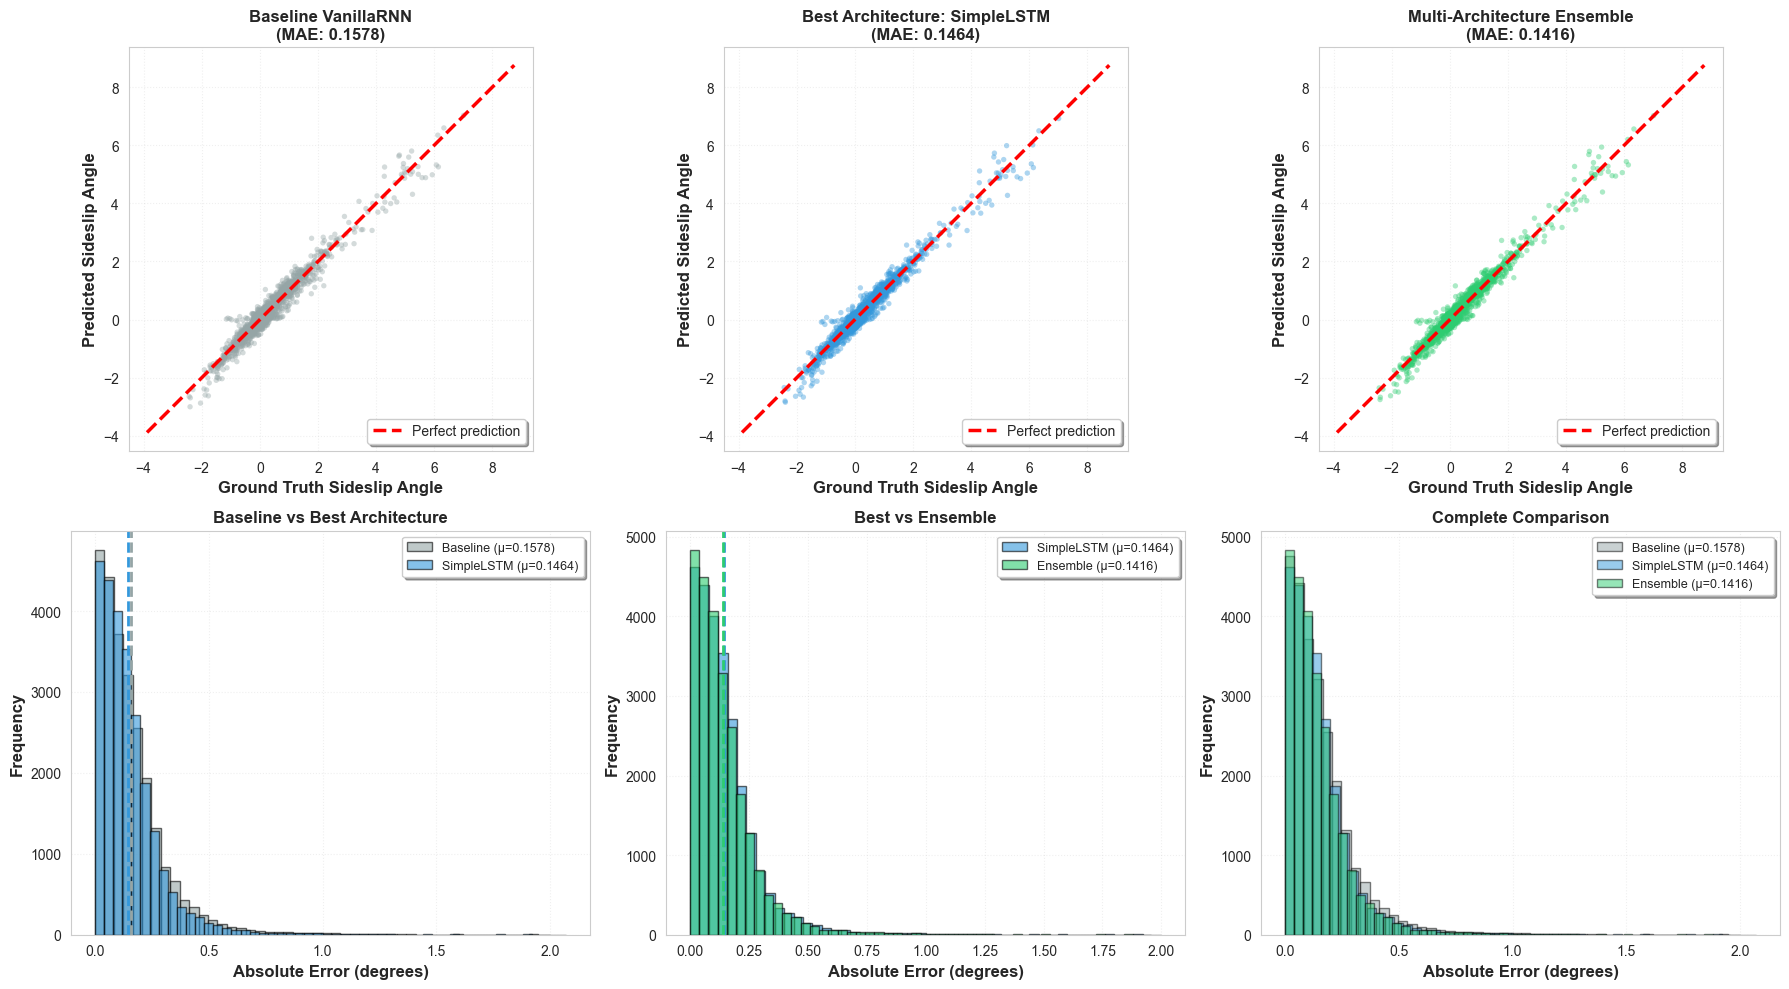


STATISTICAL COMPARISONS

1. Baseline VanillaRNN vs Ensemble:
   Baseline MAE:  0.1578 ± 0.1514
   Ensemble MAE:  0.1416 ± 0.1353
   Improvement:   10.26%
   Paired t-test: t=39.2249, p=0.000000
   ✅ Statistically significant (p < 0.05)

2. Best Architecture (SimpleLSTM) vs Ensemble:
   Best arch MAE: 0.1464 ± 0.1374
   Ensemble MAE:  0.1416 ± 0.1353
   Improvement:   3.27%
   Paired t-test: t=16.1043, p=0.000000
   ✅ Statistically significant (p < 0.05)



In [14]:
# Get best architecture predictions
best_arch_preds = architecture_predictions[best_arch_name]

# Create comparison plots: Baseline vs Best vs Ensemble
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Sample for visualization
sample_size = min(2000, len(val_targets))
indices = np.random.choice(len(val_targets), sample_size, replace=False)

# Row 1: Scatter plots
# Plot 1: Baseline
axes[0, 0].scatter(baseline_targets[indices], baseline_preds[indices], 
                alpha=0.4, s=15, c='#95a5a6', edgecolors='none')
axes[0, 0].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[0, 0].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 0].set_title(f'Baseline VanillaRNN\n(MAE: {baseline_mae:.4f})', 
                  fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='lower right', frameon=True, shadow=True)
axes[0, 0].grid(alpha=0.3, linestyle=':')
axes[0, 0].set_aspect('equal', adjustable='box')

# Plot 2: Best architecture
axes[0, 1].scatter(val_targets[indices], best_arch_preds[indices], 
                alpha=0.4, s=15, c='#3498db', edgecolors='none')
axes[0, 1].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[0, 1].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 1].set_title(f'Best Architecture: {best_arch_name}\n(MAE: {best_arch_mae:.4f})', 
                  fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='lower right', frameon=True, shadow=True)
axes[0, 1].grid(alpha=0.3, linestyle=':')
axes[0, 1].set_aspect('equal', adjustable='box')

# Plot 3: Ensemble
axes[0, 2].scatter(val_targets[indices], ensemble_preds[indices], 
                alpha=0.4, s=15, c='#2ecc71', edgecolors='none')
axes[0, 2].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[0, 2].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[0, 2].set_title(f'Multi-Architecture Ensemble\n(MAE: {ensemble_mae:.4f})', 
                  fontsize=12, fontweight='bold')
axes[0, 2].legend(loc='lower right', frameon=True, shadow=True)
axes[0, 2].grid(alpha=0.3, linestyle=':')
axes[0, 2].set_aspect('equal', adjustable='box')

# Row 2: Error distributions
baseline_errors = np.abs(baseline_preds - baseline_targets)
best_errors = np.abs(best_arch_preds - val_targets)
ensemble_errors = np.abs(ensemble_preds - val_targets)

# Plot 4: Baseline vs Best
axes[1, 0].hist(baseline_errors, bins=50, alpha=0.6,
             label=f'Baseline (μ={baseline_errors.mean():.4f})', 
             color='#95a5a6', edgecolor='black', linewidth=1)
axes[1, 0].hist(best_errors, bins=50, alpha=0.6,
             label=f'{best_arch_name} (μ={best_errors.mean():.4f})', 
             color='#3498db', edgecolor='black', linewidth=1)
axes[1, 0].axvline(x=baseline_errors.mean(), color='#95a5a6', linestyle='--', linewidth=2)
axes[1, 0].axvline(x=best_errors.mean(), color='#3498db', linestyle='--', linewidth=2)
axes[1, 0].set_xlabel('Absolute Error (degrees)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Baseline vs Best Architecture', fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='upper right', frameon=True, shadow=True, fontsize=9)
axes[1, 0].grid(alpha=0.3, linestyle=':')

# Plot 5: Best vs Ensemble
axes[1, 1].hist(best_errors, bins=50, alpha=0.6, 
             label=f'{best_arch_name} (μ={best_errors.mean():.4f})', 
             color='#3498db', edgecolor='black', linewidth=1)
axes[1, 1].hist(ensemble_errors, bins=50, alpha=0.6, 
             label=f'Ensemble (μ={ensemble_errors.mean():.4f})', 
             color='#2ecc71', edgecolor='black', linewidth=1)
axes[1, 1].axvline(x=best_errors.mean(), color='#3498db', linestyle='--', linewidth=2)
axes[1, 1].axvline(x=ensemble_errors.mean(), color='#2ecc71', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Absolute Error (degrees)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Best vs Ensemble', fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='upper right', frameon=True, shadow=True, fontsize=9)
axes[1, 1].grid(alpha=0.3, linestyle=':')

# Plot 6: All three comparison
axes[1, 2].hist(baseline_errors, bins=50, alpha=0.5, 
             label=f'Baseline (μ={baseline_errors.mean():.4f})', 
             color='#95a5a6', edgecolor='black', linewidth=1)
axes[1, 2].hist(best_errors, bins=50, alpha=0.5, 
             label=f'{best_arch_name} (μ={best_errors.mean():.4f})', 
             color='#3498db', edgecolor='black', linewidth=1)
axes[1, 2].hist(ensemble_errors, bins=50, alpha=0.5, 
             label=f'Ensemble (μ={ensemble_errors.mean():.4f})', 
             color='#2ecc71', edgecolor='black', linewidth=1)
axes[1, 2].set_xlabel('Absolute Error (degrees)', fontsize=12, fontweight='bold')
axes[1, 2].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1, 2].set_title('Complete Comparison', fontsize=12, fontweight='bold')
axes[1, 2].legend(loc='upper right', frameon=True, shadow=True, fontsize=9)
axes[1, 2].grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'baseline_best_ensemble_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Statistical comparisons
from scipy import stats

print("\n" + "="*80)
print("STATISTICAL COMPARISONS")
print("="*80)

# Baseline vs Ensemble
t_stat1, p_value1 = stats.ttest_rel(baseline_errors, ensemble_errors)
print(f"\n1. Baseline VanillaRNN vs Ensemble:")
print(f"   Baseline MAE:  {baseline_errors.mean():.4f} ± {baseline_errors.std():.4f}")
print(f"   Ensemble MAE:  {ensemble_errors.mean():.4f} ± {ensemble_errors.std():.4f}")
print(f"   Improvement:   {improvement_over_baseline:.2f}%")
print(f"   Paired t-test: t={t_stat1:.4f}, p={p_value1:.6f}")
if p_value1 < 0.05:
    print(f"   ✅ Statistically significant (p < 0.05)")
else:
    print(f"   ⚠️  Not statistically significant (p >= 0.05)")

# Best architecture vs Ensemble
t_stat2, p_value2 = stats.ttest_rel(best_errors, ensemble_errors)
print(f"\n2. Best Architecture ({best_arch_name}) vs Ensemble:")
print(f"   Best arch MAE: {best_errors.mean():.4f} ± {best_errors.std():.4f}")
print(f"   Ensemble MAE:  {ensemble_errors.mean():.4f} ± {ensemble_errors.std():.4f}")
print(f"   Improvement:   {improvement_over_best:.2f}%")
print(f"   Paired t-test: t={t_stat2:.4f}, p={p_value2:.6f}")
if p_value2 < 0.05:
    print(f"   ✅ Statistically significant (p < 0.05)")
else:
    print(f"   ⚠️  Not statistically significant (p >= 0.05)")

print("="*80 + "\n")

## 8. Test Set Inference

### 8.1 Load Test Data

In [15]:
# Load test dataset
columns_to_drop = ['sideSlip', 'vyCG', 'latitude', 'longitude', 'time']
test_loader = load_test_data(
    test_path=str(TEST_PATH),
    scaler=scaler,
    columns_to_drop=columns_to_drop,
    sequence_length=SEQUENCE_LENGTH,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=BATCH_SIZE,
    seed=SEED
)

print(f"Test set batches: {len(test_loader)}")
print(f"Approximate test samples: {len(test_loader) * BATCH_SIZE:,}")

📂 Loading Test Data (V1-Compatible)

Found 11 test files
🔧 Applying threshold per file: vxCG > 3.0 (grouping)

   test_part_001.csv         | 4 groups, 1,428 samples
   test_part_002.csv         | 1 groups, 10,190 samples
   test_part_003.csv         | No valid groups
   test_part_004.csv         | 2 groups, 6,914 samples
   test_part_005.csv         | 1 groups, 11,260 samples
   test_part_006.csv         | 1 groups, 10,256 samples
   test_part_007.csv         | 2 groups, 389 samples
   test_part_008.csv         | 2 groups, 3,177 samples
   test_part_009.csv         | 1 groups, 1,595 samples
   test_part_010.csv         | 1 groups, 3,168 samples
   test_part_011.csv         | 1 groups, 1,271 samples

✅ Total groups: 16

📊 Test Data Summary:
   Raw samples: 68,806
   After threshold: 49,648 (removed 19,158)
   Expected sequences: 49,628 (Kaggle expects 49,328)

✅ Test sequences: 49,328
   ✅ Count matches Kaggle requirement!

Test set batches: 193
Approximate test samples: 49,408


### 8.2 Generate Test Predictions from All Architectures

In [16]:
# Generate predictions from each architecture
test_predictions = {}

print("\n" + "="*80)
print("GENERATING TEST PREDICTIONS")
print("="*80)

for arch_name, model in trained_models.items():
    model.eval()
    arch_preds = []
    
    with torch.no_grad():
        for X in tqdm(test_loader, desc=f"{arch_name} inference"):
            X = X.to(device)
            pred = model(X).cpu().numpy().flatten()
            arch_preds.extend(pred)
    
    test_predictions[arch_name] = np.array(arch_preds)
    print(f"  {arch_name}: {len(arch_preds):,} predictions")

# Create ensemble prediction
test_all_preds = np.stack([test_predictions[name] for name in ARCHITECTURES.keys()], axis=0)
test_ensemble_preds = np.mean(test_all_preds, axis=0)

print(f"\n✅ Generated ensemble predictions: {len(test_ensemble_preds):,}")
print("="*80)


GENERATING TEST PREDICTIONS


VanillaRNN inference: 100%|██████████| 193/193 [00:00<00:00, 649.13it/s]


  VanillaRNN: 49,328 predictions


SimpleLSTM inference: 100%|██████████| 193/193 [00:00<00:00, 645.56it/s]


  SimpleLSTM: 49,328 predictions


SimpleGRU inference: 100%|██████████| 193/193 [00:00<00:00, 686.20it/s]


  SimpleGRU: 49,328 predictions


SimpleBiLSTM inference: 100%|██████████| 193/193 [00:00<00:00, 669.98it/s]


  SimpleBiLSTM: 49,328 predictions


BiLSTMAttention inference: 100%|██████████| 193/193 [00:00<00:00, 398.06it/s]

  BiLSTMAttention: 49,328 predictions

✅ Generated ensemble predictions: 49,328


### 8.3 Create Submission Files

Generate three submissions: baseline VanillaRNN, best individual architecture from ensemble, and multi-architecture ensemble.

In [17]:
# Generate timestamp
timestamp = datetime.now().strftime("%Y%m%d_%H%M")

print("\n" + "="*80)
print("CREATING SUBMISSION FILES")
print("="*80)

# 1. Baseline VanillaRNN submission
baseline_test_preds = []
baseline_model.eval()

with torch.no_grad():
    for X in tqdm(test_loader, desc="Baseline inference"):
        X = X.to(device)
        pred = baseline_model(X).cpu().numpy().flatten()
        baseline_test_preds.extend(pred)

baseline_test_preds = np.array(baseline_test_preds)

baseline_submission_df = pd.DataFrame({
    'id': range(len(baseline_test_preds)),
    'predicted_sideslip': baseline_test_preds
})

baseline_submission_filename = (
    f"submission_baseline_VanillaRNN_"
    f"MAE{baseline_mae:.4f}_{timestamp}.csv"
)
baseline_submission_path = OUTPUT_DIR / baseline_submission_filename
baseline_submission_df.to_csv(baseline_submission_path, index=False)

print(f"\n[1/3] Baseline VanillaRNN: {baseline_submission_path.name}")
print(f"      Validation MAE: {baseline_mae:.4f}")

# 2. Best individual architecture submission
best_test_preds = test_predictions[best_arch_name]
best_submission_df = pd.DataFrame({
    'id': range(len(best_test_preds)),
    'predicted_sideslip': best_test_preds
})

best_submission_filename = (
    f"submission_best_{best_arch_name}_"
    f"MAE{best_arch_mae:.4f}_{timestamp}.csv"
)
best_submission_path = OUTPUT_DIR / best_submission_filename
best_submission_df.to_csv(best_submission_path, index=False)

print(f"\n[2/3] Best architecture: {best_submission_path.name}")
print(f"      Architecture: {best_arch_name}")
print(f"      Validation MAE: {best_arch_mae:.4f}")

# 3. Multi-architecture ensemble submission
ensemble_submission_df = pd.DataFrame({
    'id': range(len(test_ensemble_preds)),
    'predicted_sideslip': test_ensemble_preds
})

ensemble_submission_filename = (
    f"submission_multiarch_ensemble_"
    f"N{len(ARCHITECTURES)}_MAE{ensemble_mae:.4f}_{timestamp}.csv"
)
ensemble_submission_path = OUTPUT_DIR / ensemble_submission_filename
ensemble_submission_df.to_csv(ensemble_submission_path, index=False)

print(f"\n[3/3] Multi-architecture ensemble: {ensemble_submission_path.name}")
print(f"      Architectures: {len(ARCHITECTURES)} ({', '.join(ARCHITECTURES.keys())})")
print(f"      Validation MAE: {ensemble_mae:.4f}")
print(f"      Expected improvement over baseline: {improvement_over_baseline:+.2f}%")
print(f"      Expected improvement over best: {improvement_over_best:+.2f}%")

print("\n" + "="*80)
print("SUBMISSION SUMMARY")
print("="*80)
print(f"Baseline VanillaRNN:         {baseline_submission_path.name}")
print(f"Best individual ({best_arch_name}): {best_submission_path.name}")
print(f"Multi-arch Ensemble:         {ensemble_submission_path.name}")
print(f"\nSubmit all three files to compare:")
print(f"  1. Baseline single-architecture performance")
print(f"  2. Best architecture from diverse ensemble members")
print(f"  3. Multi-architecture ensemble aggregation")
print("="*80 + "\n")

# Display previews
print("\nBaseline submission preview:")
print(baseline_submission_df.head(10))
print(f"\nBest architecture submission preview:")
print(best_submission_df.head(10))
print(f"\nEnsemble submission preview:")
print(ensemble_submission_df.head(10))
print(f"\nTotal predictions per file: {len(baseline_submission_df):,}")


CREATING SUBMISSION FILES


Baseline inference: 100%|██████████| 193/193 [00:00<00:00, 698.87it/s]



[1/3] Baseline VanillaRNN: submission_baseline_VanillaRNN_MAE0.1578_20260209_1909.csv
      Validation MAE: 0.1578

[2/3] Best architecture: submission_best_SimpleLSTM_MAE0.1464_20260209_1909.csv
      Architecture: SimpleLSTM
      Validation MAE: 0.1464

[3/3] Multi-architecture ensemble: submission_multiarch_ensemble_N5_MAE0.1416_20260209_1909.csv
      Architectures: 5 (VanillaRNN, SimpleLSTM, SimpleGRU, SimpleBiLSTM, BiLSTMAttention)
      Validation MAE: 0.1416
      Expected improvement over baseline: +10.26%
      Expected improvement over best: +3.27%

SUBMISSION SUMMARY
Baseline VanillaRNN:         submission_baseline_VanillaRNN_MAE0.1578_20260209_1909.csv
Best individual (SimpleLSTM): submission_best_SimpleLSTM_MAE0.1464_20260209_1909.csv
Multi-arch Ensemble:         submission_multiarch_ensemble_N5_MAE0.1416_20260209_1909.csv

Submit all three files to compare:
  1. Baseline single-architecture performance
  2. Best architecture from diverse ensemble members
  3. Multi-arc

## 9. Model Persistence

### 9.1 Save All Models and Configuration

In [19]:
# Create model checkpoint directory
model_save_dir = OUTPUT_DIR / "multi_architecture_models"
model_save_dir.mkdir(exist_ok=True)

# Save individual models
print("Saving trained models...")
for arch_name, model in trained_models.items():
    checkpoint = {
        'architecture': arch_name,
        'model_state_dict': model.state_dict(),
        'model_class': ARCHITECTURES[arch_name]['class'].__name__,
        'model_params': ARCHITECTURES[arch_name]['params'],
        'metrics': architecture_metrics[arch_name],
        'training_history': architecture_histories[arch_name]
    }
    
    model_path = model_save_dir / f"{arch_name}.pth"
    torch.save(checkpoint, model_path)
    print(f"  ✅ {arch_name}")

# Save ensemble configuration
config = {
    'experiment_name': 'multi_architecture_ensemble',
    'timestamp': timestamp,
    'seed': SEED,
    'num_architectures': len(ARCHITECTURES),
    'architectures': list(ARCHITECTURES.keys()),
    'training_config': {
        'epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'sequence_length': SEQUENCE_LENGTH,
        'hidden_size': HIDDEN_SIZE
    },
    'performance': {
        'baseline_mae': float(baseline_mae),
        'ensemble_mae': float(ensemble_mae),
        'best_architecture': best_arch_name,
        'best_architecture_mae': float(best_arch_mae),
        'mean_architecture_mae': float(mean_arch_mae),
        'improvement_over_baseline_pct': float(improvement_over_baseline),
        'improvement_over_best_pct': float(improvement_over_best),
        'improvement_over_mean_pct': float(improvement_over_mean),
        'individual_architectures': {name: float(architecture_metrics[name]['val_mae']) 
                                    for name in ARCHITECTURES.keys()}
    },
    'diversity': {
        'mean_correlation': float(mean_correlation),
        'min_correlation': float(min_correlation),
        'max_correlation': float(max_correlation)
    },
    'submission_files': {
        'baseline': str(baseline_submission_path.name),
        'best_architecture': str(best_submission_path.name),
        'ensemble': str(ensemble_submission_path.name)
    }
}

import json
config_path = OUTPUT_DIR / f"multi_architecture_config_{timestamp}.json"
with open(config_path, 'w') as f:
    json.dump(config, f, indent=2)

print(f"\n✅ Configuration saved: {config_path.name}")

Saving trained models...
  ✅ VanillaRNN
  ✅ SimpleLSTM
  ✅ SimpleGRU
  ✅ SimpleBiLSTM
  ✅ BiLSTMAttention

✅ Configuration saved: multi_architecture_config_20260209_1909.json


## 10. Summary and Conclusions

### 10.1 Experimental Results

In [20]:
print("\n" + "="*80)
print("MULTI-ARCHITECTURE ENSEMBLE RESULTS")
print("="*80)

print("\n1. EXPERIMENTAL SETUP")
print("-" * 80)
print(f"   Number of architectures:  {len(ARCHITECTURES)}")
print(f"   Random seed:              {SEED} (same for all)")
print(f"   Training epochs:          {NUM_EPOCHS}")

print("\n2. INDIVIDUAL ARCHITECTURE PERFORMANCE")
print("-" * 80)
for i, row in summary_df.iterrows():
    marker = "🏆" if row['Architecture'] == best_arch_name else "  "
    print(f"   {marker} {row['Architecture']:20s}: {row['Val_MAE']:.4f}")
print(f"\n   Range: {summary_df['Val_MAE'].min():.4f} - {summary_df['Val_MAE'].max():.4f}")
print(f"   Std:   {summary_df['Val_MAE'].std():.4f}")

print("\n3. ENSEMBLE PERFORMANCE")
print("-" * 80)
print(f"   Baseline VanillaRNN MAE:     {baseline_mae:.4f} (standalone)")
print(f"   Ensemble MAE:                {ensemble_mae:.4f}")
print(f"   Best architecture MAE:       {best_arch_mae:.4f} ({best_arch_name})")
print(f"   Improvement over baseline:   {improvement_over_baseline:+.2f}%")
print(f"   Improvement over best:       {improvement_over_best:+.2f}%")

print("\n4. DIVERSITY ANALYSIS")
print("-" * 80)
print(f"   Mean prediction correlation: {mean_correlation:.4f}")
print(f"   Correlation range:           {min_correlation:.4f} - {max_correlation:.4f}")

print("\n5. INTERPRETATION")
print("-" * 80)
if improvement_over_best > 0:
    print("   ✅ Multi-architecture ensemble BEATS best individual!")
    print(f"      This demonstrates the value of architectural diversity.")
    print(f"      Different architectures make complementary errors that")
    print(f"      cancel out when averaged.")
else:
    print("   ⚠️  Multi-architecture ensemble does NOT beat best individual.")
    print(f"      Possible reasons:")
    print(f"      - Architectures too similar (high mean correlation)")
    print(f"      - Best architecture already near optimal")
    print(f"      - Validation/test distribution mismatch")

print("\n6. SUBMISSION FILES")
print("-" * 80)
print(f"   Baseline:  {baseline_submission_path.name}")
print(f"   Best arch: {best_submission_path.name}")
print(f"   Ensemble:  {ensemble_submission_path.name}")

print("\n" + "="*80)
print("CONCLUSION")
print("="*80)
print(f"The multi-architecture ensemble approach with {len(ARCHITECTURES)} diverse RNN architectures")
print(f"achieved a validation MAE of {ensemble_mae:.4f}, representing a {abs(improvement_over_baseline):.2f}%")
print(f"improvement over the baseline VanillaRNN ({baseline_mae:.4f}) and {abs(improvement_over_best):.2f}%")
if improvement_over_best > 0:
    print(f"improvement over the best architecture ({best_arch_name}: {best_arch_mae:.4f}).")
    print(f"The architectural diversity (mean correlation: {mean_correlation:.4f}) successfully")
    print(f"created complementary error profiles that improved generalization.")
else:
    print(f"change vs the best architecture ({best_arch_name}: {best_arch_mae:.4f}).")
    print(f"However, it still outperforms the baseline, demonstrating value in architectural diversity.")

print("="*80 + "\n")


MULTI-ARCHITECTURE ENSEMBLE RESULTS

1. EXPERIMENTAL SETUP
--------------------------------------------------------------------------------
   Number of architectures:  5
   Random seed:              42 (same for all)
   Training epochs:          50

2. INDIVIDUAL ARCHITECTURE PERFORMANCE
--------------------------------------------------------------------------------
   🏆 SimpleLSTM          : 0.1464
      SimpleBiLSTM        : 0.1473
      SimpleGRU           : 0.1485
      BiLSTMAttention     : 0.1499
      VanillaRNN          : 0.1578

   Range: 0.1464 - 0.1578
   Std:   0.0046

3. ENSEMBLE PERFORMANCE
--------------------------------------------------------------------------------
   Baseline VanillaRNN MAE:     0.1578 (standalone)
   Ensemble MAE:                0.1416
   Best architecture MAE:       0.1464 (SimpleLSTM)
   Improvement over baseline:   +10.26%
   Improvement over best:       +3.27%

4. DIVERSITY ANALYSIS
-----------------------------------------------------------